# Milestone 1: Data Profiling and Quality Audit with DuckDB
## Data Engineering Lifecycle - BTS Airline Flight Delays Dataset

### 1. Executive Summary and Lifecycle Context
In the modern Data Engineering Lifecycle, raw telemetry and production operational data are inherently noisy—suffering from transmission drops, reporting anomalies, system updates, and formatting discrepancies. Direct ingestion of unverified data into analytical platforms or AI models leads to degraded performance and invalid business decisions.

**Milestone 1 Objectives:**
1. **Schema Discovery:** Inspect dataset schema and column metadata directly from storage using **DuckDB** without full RAM ingestion.
2. **Analytical SQL Profiling:** Quantify data completeness, compute extreme boundaries, and uncover underlying distributions.
3. **Anomaly Identification:** Detect technical glitches (e.g., component sum mismatches) and understand domain-specific attributes (e.g., fractional attribution of delay causes).
4. **Preparation for Milestone 2 & 3:** Establish baseline data quality rules for cleaning, physical partitioning (PyArrow/Polars), and feature serving (Scikit-learn).

### Why DuckDB?
* **In-process OLAP engine:** Operates directly within the Python process memory space without external database server overhead.
* **Vectorized Execution Kernel:** Processes data in columnar chunks (vector batches), maximizing CPU cache locality and SIMD execution.
* **Zero-Copy & Memory Efficiency:** Directly streams and queries files from disk without duplicating raw records into system RAM.

In [1]:
# Step 0: Environment Setup and Dependencies
import sys
from pathlib import Path

# Add repository root to Python path
ROOT_DIR = Path("..").resolve()
if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))

import duckdb
import polars as pl
import pyarrow as pa
import matplotlib.pyplot as plt
import seaborn as sns

from src.config import BTS_CSV_PATH, RAW_DATA_DIR
from src.profiling import get_duckdb_connection, get_schema_description, profile_bts_flight_delays

print(f"DuckDB version: {duckdb.__version__}")
print(f"Polars version: {pl.__version__}")
print(f"PyArrow version: {pa.__version__}")
print(f"Raw dataset path: {BTS_CSV_PATH}")

DuckDB version: 1.4.5
Polars version: 1.36.1
PyArrow version: 21.0.0
Raw dataset path: /Users/michalozminkowski/Documents/Informatyka/Rok 4/Big Data/big-data-exercise-2026/data/raw/Airline_Delay_Cause.csv


### 2. Schema Discovery (Zero Full-Load)
Using DuckDB to inspect the file schema using `DESCRIBE SELECT * FROM '<file>'` without materializing the dataset into RAM.

In [2]:
con = get_duckdb_connection()
schema_df = get_schema_description(str(BTS_CSV_PATH), con=con)
schema_df

,column_name,column_type,null,key,default,extra
0,year,BIGINT,YES,None,None,None
1,month,BIGINT,YES,None,None,None
2,carrier,VARCHAR,YES,None,None,None
3,carrier_name,VARCHAR,YES,None,None,None
4,airport,VARCHAR,YES,None,None,None
5,airport_name,VARCHAR,YES,None,None,None
6,arr_flights,BIGINT,YES,None,None,None
7,arr_del15,BIGINT,YES,None,None,None
8,carrier_ct,DOUBLE,YES,None,None,None
9,weather_ct,DOUBLE,YES,None,None,None


### 3. Comprehensive Data Profiling with DuckDB SQL
Here we execute an analytical aggregation query to measure:
* Total records and completeness per column (NULL counts).
* Min, max, and average values across all numeric indicators.
* Data coverage timeline (years, months, airlines, airports).

In [3]:
profiles = profile_bts_flight_delays(str(BTS_CSV_PATH), con=con)

print("=== COMPLETENESS AND NULL AUDIT ===")
display(profiles["null_profile"])

print("\n=== DESCRIPTIVE SUMMARY STATISTICS ===")
display(profiles["descriptive_stats"].T)

=== COMPLETENESS AND NULL AUDIT ===


,metric,value
0,total_rows,398233
1,null_year,0
2,null_month,0
3,null_carrier,0
4,null_carrier_name,0
5,null_airport,0
6,null_airport_name,0
7,null_arr_flights,657
8,null_arr_del15,950
9,null_carrier_ct,657



=== DESCRIPTIVE SUMMARY STATISTICS ===


,0
min_year,2003.00
max_year,2025.00
min_month,1.00
max_month,12.00
min_arr_flights,1.00
max_arr_flights,21977.00
avg_arr_flights,361.66
min_arr_del15,0.00
max_arr_del15,6377.00
avg_arr_del15,69.59


### 4. Technical and Domain Anomaly Detection
We audit the dataset for mathematical invariants and known domain characteristics:
1. **Component sum mismatch:** Does `arr_delay == carrier_delay + weather_delay + nas_delay + security_delay + late_aircraft_delay`?
2. **Fractional flight counts:** Why are columns like `carrier_ct` floating-point numbers instead of integers?
3. **100% cancellation periods:** Months where scheduled operations collapsed completely.

In [4]:
print("=== DETECTED ANOMALIES & INTEGRITY CHECKS ===")
display(profiles["anomalies"])

# Inspect specific rows with component sum mismatch
mismatch_query = f"""
SELECT year, month, carrier, airport, arr_flights, arr_del15, arr_delay,
       (carrier_delay + weather_delay + nas_delay + security_delay + late_aircraft_delay) AS calculated_sum,
       arr_delay - (carrier_delay + weather_delay + nas_delay + security_delay + late_aircraft_delay) AS delay_difference
FROM '{BTS_CSV_PATH}'
WHERE ABS(arr_delay - (carrier_delay + weather_delay + nas_delay + security_delay + late_aircraft_delay)) > 1
"""
df_mismatches = con.execute(mismatch_query).df()
print(f"\nTotal mismatch instances: {len(df_mismatches)}")
display(df_mismatches.head(10))

=== DETECTED ANOMALIES & INTEGRITY CHECKS ===


,anomaly_type,detected_count
0,zero_or_negative_flights,0
1,delayed_exceeds_total_flights,0
2,cancelled_exceeds_total_flights,0
3,negative_delay_minutes,0
4,delay_components_sum_mismatch,9
5,fractional_carrier_counts,327994
6,all_flights_cancelled_records,270



Total mismatch instances: 9


,year,month,carrier,airport,arr_flights,arr_del15,arr_delay,calculated_sum,delay_difference
0,2024,7,F9,MCO,1274,393,39334,39154,180
1,2024,7,F9,MIA,372,136,12812,12686,126
2,2024,1,C5,BRO,101,21,2773,1428,1345
3,2023,11,F9,CLE,492,99,6934,6880,54
4,2023,10,UA,DCA,538,56,3006,2775,231
5,2022,1,ZW,AVP,64,17,1313,1077,236
6,2021,3,F9,STL,87,17,559,539,20
7,2020,8,DL,SEA,1842,127,7690,7181,509
8,2017,8,F9,TTN,187,44,4044,3850,194


### Domain Interpretation of Anomalies
* **Fractional Counts (`carrier_ct`, `weather_ct`, etc.):** When a single flight delay is attributed to multiple causes (e.g. bad weather cascading into late turnaround equipment), the US Department of Transportation allocates proportional weights (e.g. 0.5 to weather, 0.5 to late aircraft). Thus, counts are non-integers by regulatory design.
* **Component Sum Discrepancy:** The 9 records with discrepancies reflect retroactive reporting corrections or non-standard delay classifications in specific carrier reporting systems.
* **NULL Values (657 rows):** 657 monthly records contain NULL values for delay categories. These correspond to months where flights were scheduled but no actual operations took place or data submission was incomplete.

### 5. Analytical Aggregations and Visual Insights
Deep-dive OLAP queries to visualize delay distributions by airline, airport, and historical trends.

In [5]:
# Top 10 Major Airports by Total Arrival Delay Volume
top_airports_query = f"""
SELECT 
    airport,
    airport_name,
    SUM(arr_flights) AS total_flights,
    SUM(arr_del15) AS total_delayed_flights,
    ROUND(SUM(arr_del15) * 100.0 / NULLIF(SUM(arr_flights), 0), 2) AS delay_percentage,
    ROUND(SUM(arr_delay) / 60.0 / 1000.0, 1) AS total_delay_thousands_of_hours
FROM '{BTS_CSV_PATH}'
WHERE arr_flights > 0
GROUP BY airport, airport_name
HAVING SUM(arr_flights) > 1000000
ORDER BY delay_percentage DESC
LIMIT 10
"""
df_top_airports = con.execute(top_airports_query).df()
display(df_top_airports)

,airport,airport_name,total_flights,total_delayed_flights,delay_percentage,total_delay_thousands_of_hours
0,EWR,"Newark, NJ: Newark Liberty International",2848697.0,776477.0,27.26,931.1
1,SFO,"San Francisco, CA: San Francisco International",3146031.0,768136.0,24.42,828.1
2,LGA,"New York, NY: LaGuardia",2613232.0,625661.0,23.94,688.2
3,JFK,"New York, NY: John F. Kennedy International",2321380.0,532103.0,22.92,609.2
4,FLL,"Fort Lauderdale, FL: Fort Lauderdale-Hollywood...",1637828.0,360394.0,22.00,355.7
5,BOS,"Boston, MA: Logan International",2633735.0,567662.0,21.55,604.4
6,ORD,"Chicago, IL: Chicago O'Hare International",6938498.0,1486102.0,21.42,1781.3
7,PHL,"Philadelphia, PA: Philadelphia International",2191500.0,462947.0,21.12,493.5
8,MCO,"Orlando, FL: Orlando International",2746124.0,561299.0,20.44,564.4
9,RDU,"Raleigh/Durham, NC: Raleigh-Durham International",1119283.0,228421.0,20.41,224.2


/var/folders/b4/9q44p2zn7s7_p109gy775q700000gn/T/ipykernel_56331/1621530758.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_top_airports, x="airport", y="delay_percentage", palette="magma")


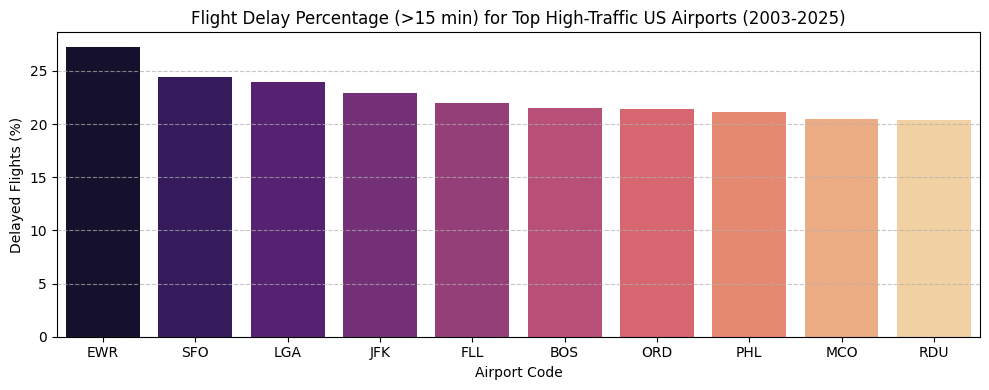

In [6]:
# Visualization: Delay Percentage across Top High-Traffic Airports
plt.figure(figsize=(10, 4))
sns.barplot(data=df_top_airports, x="airport", y="delay_percentage", palette="magma")
plt.title("Flight Delay Percentage (>15 min) for Top High-Traffic US Airports (2003-2025)")
plt.ylabel("Delayed Flights (%)")
plt.xlabel("Airport Code")
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

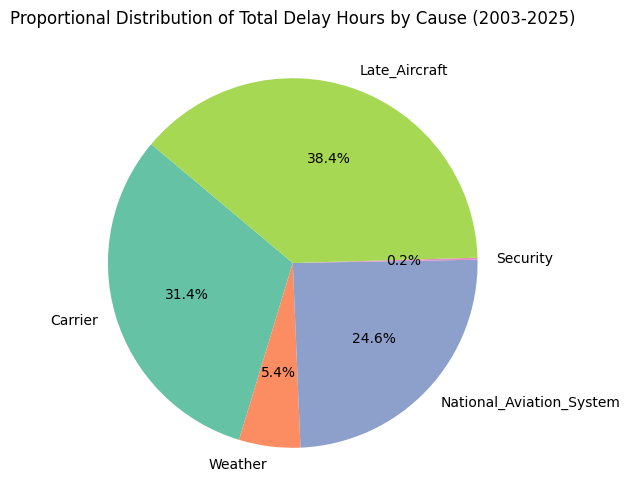

In [7]:
# Delay Cause Breakdown across Entire Dataset
causes_query = f"""
SELECT
    ROUND(SUM(carrier_delay) / 60.0 / 1000.0, 1) AS Carrier,
    ROUND(SUM(weather_delay) / 60.0 / 1000.0, 1) AS Weather,
    ROUND(SUM(nas_delay) / 60.0 / 1000.0, 1) AS National_Aviation_System,
    ROUND(SUM(security_delay) / 60.0 / 1000.0, 1) AS Security,
    ROUND(SUM(late_aircraft_delay) / 60.0 / 1000.0, 1) AS Late_Aircraft
FROM '{BTS_CSV_PATH}'
"""
df_causes = con.execute(causes_query).df()
causes_series = df_causes.iloc[0]

plt.figure(figsize=(6, 6))
plt.pie(causes_series, labels=causes_series.index, autopct="%1.1f%%", startangle=140, colors=sns.color_palette("Set2"))
plt.title("Proportional Distribution of Total Delay Hours by Cause (2003-2025)")
plt.show()

### 6. Strategic Conclusions for Next Milestones

#### Milestone 2 (Data Transformation & Physical Partitioning):
* **Partitioning Strategy:** Partition data by `year` (23 partitions) or `(year, carrier)`. This yields natural cardinalities for partition pruning.
* **Storage Format:** Convert raw CSV to Snappy-compressed Parquet with columnar encodings.
* **Cleaning Rules:** Handle 657 NULL records; flag or correct 9 component mismatch rows.

#### Milestone 3 (AI / Machine Learning Serving):
* **Problem Formulation:** Predict `arr_del15` (delayed flight probability) or `arr_delay` (delay duration in minutes) based on historical carrier performance, seasonality (`month`), and airport traffic.
* **Feature Engineering:** Historical airport congestion rate, carrier on-time score, monthly seasonality index.